# Aula 9 — Princípios de visualização de dados e escolha de gráficos



## 1. Da pergunta ao gráfico — notebook e leitura da base

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

**Célula opcional.** Usamos a mesma base das Aulas 7 e 8 (`pacientes_aula8_analise.csv`).
Se o arquivo **não** estiver na pasta do notebook, a célula abaixo cria uma base **sintética** com as mesmas colunas, apenas para que o notebook rode. Se o arquivo existir, ela não faz nada.

In [11]:
from pathlib import Path

if not Path("pacientes_aula8_analise.csv").exists():
    rng = np.random.default_rng(42)
    n = 300
    idade = rng.integers(18, 95, n)
    servico = rng.choice(["Cardio", "Neuro", "Orto", "Pneumo"], n, p=[0.35, 0.25, 0.2, 0.2])
    tempo = np.round(rng.gamma(2.0, 2.0 + idade / 40)).astype(int) + 1
    tempo[rng.choice(n, 6, replace=False)] += rng.integers(15, 30, 6)  # alguns casos longos
    internacoes = rng.poisson(0.5 + idade / 50)
    p_readm = 1 / (1 + np.exp(-(-3.2 + 0.02 * idade + 0.05 * tempo + 0.3 * internacoes)))
    readmissao = rng.binomial(1, p_readm)
    data_alta = pd.Timestamp("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D")
    pd.DataFrame({
        "id_paciente": np.arange(1, n + 1),
        "idade": idade,
        "faixa_etaria": pd.cut(idade, [0, 39, 59, 120], labels=["18-39", "40-59", "60+"]).astype(str),
        "servico": servico,
        "tempo_internacao_dias": tempo,
        "internacoes_anteriores": internacoes,
        "readmissao_30d": readmissao,
        "data_alta": data_alta.strftime("%Y-%m-%d"),
    }).to_csv("pacientes_aula8_analise.csv", index=False)


In [12]:
df = pd.read_csv("pacientes_aula8_analise.csv")
df.head()

,id_paciente,idade,faixa_etaria,servico,tempo_internacao_dias,internacoes_anteriores,readmissao_30d,data_alta
0,1,24,18-39,Pneumo,7,4,1,2025-11-04
1,2,77,60+,Pneumo,2,1,1,2025-10-21
2,3,68,60+,Cardio,5,2,0,2025-08-08
3,4,51,40-59,Neuro,3,2,0,2025-07-09
4,5,51,40-59,Cardio,8,2,0,2025-11-09


## 2. Distribuição

**Pergunta:** como se distribui o tempo de internação?

*Histograma — mostra concentração, assimetria, múltiplos picos e caudas longas; não mostra cada paciente individualmente.*

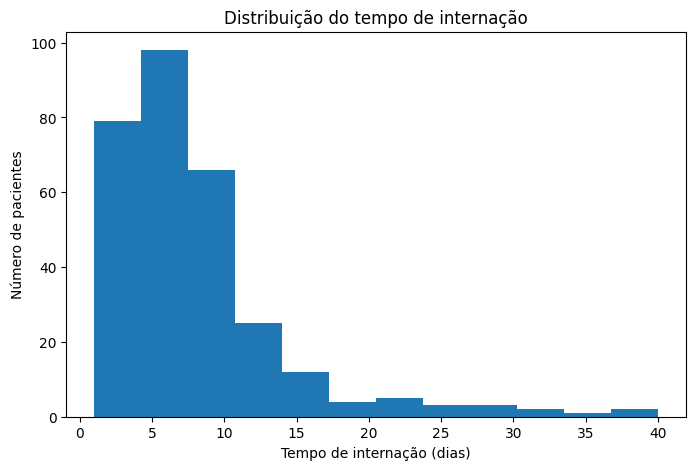

In [13]:
plt.figure(figsize=(8, 5)) # O figsize recebe os valores em polegadas
plt.hist(df["tempo_internacao_dias"].dropna(), bins=12)
plt.xlabel("Tempo de internação (dias)")
plt.ylabel("Número de pacientes")
plt.title("Distribuição do tempo de internação")
plt.show()

### Os bins mudam a mensagem

**Pergunta:** qual representação mostra melhor a estrutura sem criar detalhes artificiais?

Poucos intervalos:

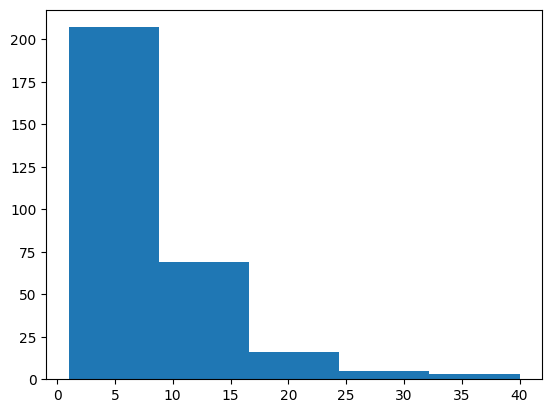

In [27]:
plt.hist(
    df["tempo_internacao_dias"].dropna(),
    bins=5
)
plt.show()

Muitos intervalos:

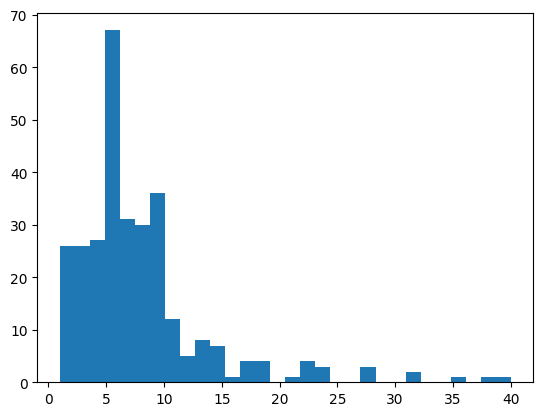

In [28]:
plt.hist(
    df["tempo_internacao_dias"].dropna(),
    bins=30
)
plt.show()

### Boxplot: resumo compacto da distribuição

**Pergunta:** qual é a mediana, a região central e quais valores merecem inspeção?

*Linha central = mediana; caixa = Q1 a Q3; pontos além = candidatos à inspeção, não à remoção.*


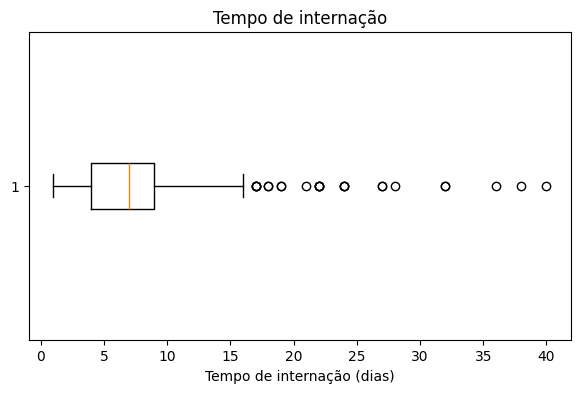

In [16]:
plt.figure(figsize=(7, 4))
plt.boxplot(df["tempo_internacao_dias"].dropna(), orientation="horizontal")
plt.xlabel("Tempo de internação (dias)")
plt.title("Tempo de internação")
plt.show()

### Comparando distribuições entre grupos

**Pergunta:** o tempo de internação se distribui de forma diferente entre os serviços?



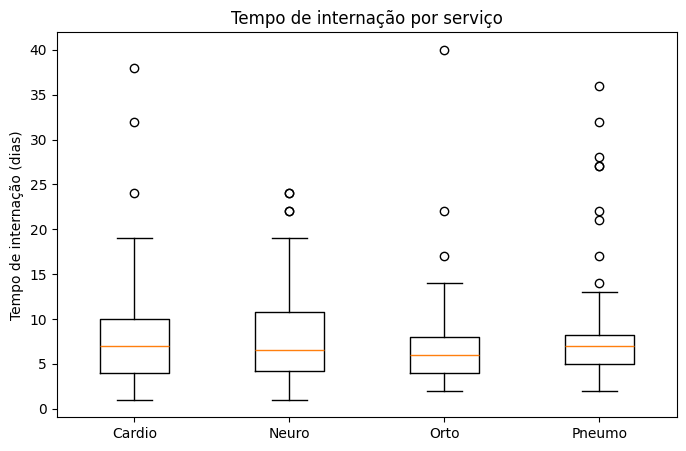

In [17]:
grupos = [
    g["tempo_internacao_dias"].dropna().values
    for _, g in df.groupby("servico")
] # O _ recebe o nome do serviço, enquanto g recebe as linhas do DataFrame pertencentes àquele serviço.
rotulos = list(df.groupby("servico").groups.keys())

plt.figure(figsize=(8, 5))
plt.boxplot(grupos, tick_labels=rotulos)
plt.ylabel("Tempo de internação (dias)")
plt.title("Tempo de internação por serviço")
plt.show()

## 3. Categorias e tempo

### Barras: readmissão por serviço

**Pergunta:** qual serviço tem maior proporção de readmissão em 30 dias?

*Como `readmissao_30d` é 0/1, a média por grupo é a proporção. Ordenar as barras facilita a comparação.*

Preparação:

In [18]:
taxa_servico = (
    df.groupby("servico")["readmissao_30d"]
      .mean()
      .sort_values(ascending=False)
)

Gráfico:

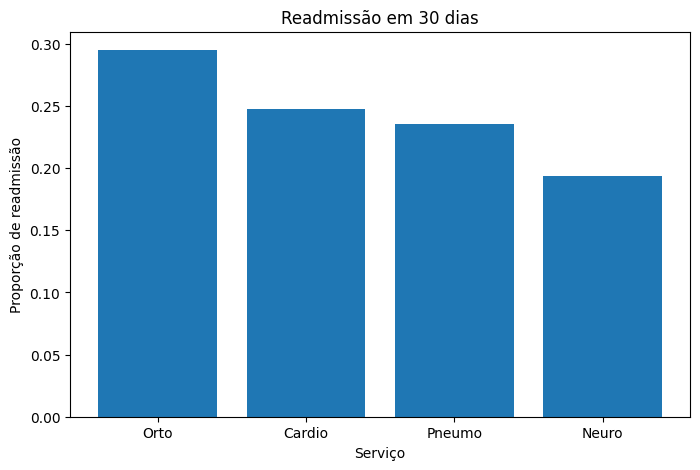

In [19]:
plt.figure(figsize=(8, 5))
plt.bar(
    taxa_servico.index,
    taxa_servico.values
)
plt.ylabel("Proporção de readmissão")
plt.xlabel("Serviço")
plt.title("Readmissão em 30 dias")
plt.show()

### Série temporal: a readmissão mudou ao longo dos meses?

**Pergunta:** a proporção de readmissão mudou ao longo dos meses?

*Só se a base tiver a coluna `data_alta`.*

Variável mensal:

In [20]:
# Converter a coluna data_alta para data
df["data_alta"] = pd.to_datetime(
    df["data_alta"], errors="coerce"
)

# Criar uma coluna com o mês da alta
df["mes_alta"] = (
    df["data_alta"]
      .dt.to_period("M")
      .astype(str)
)

taxa_mes = (
    df.groupby("mes_alta")["readmissao_30d"].mean()
)

Gráfico:

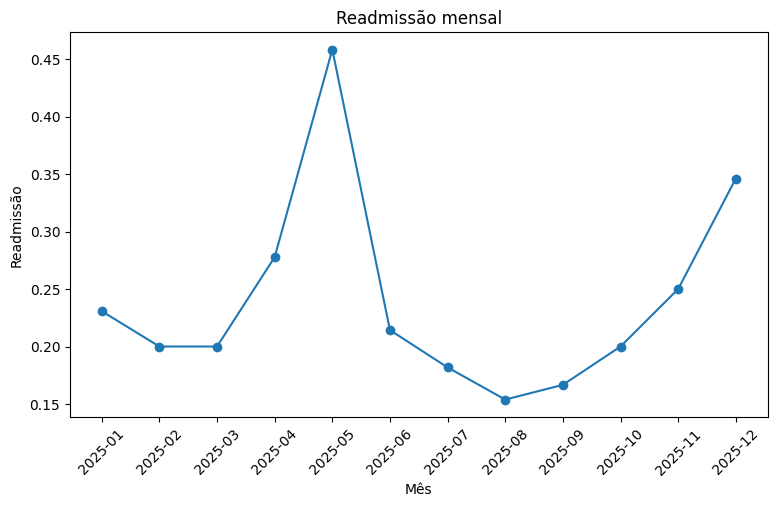

In [21]:
plt.figure(figsize=(9, 5))
plt.plot(
    taxa_mes.index,
    taxa_mes.values,
    marker="o"
)
plt.xlabel("Mês")
plt.ylabel("Readmissão")
plt.title("Readmissão mensal")
plt.xticks(rotation=45)
plt.show()

*A linha sugere continuidade e ordem entre os pontos; não prova uma mudança estatisticamente significativa.*

## 4. Relações e matrizes

### Dispersão

**Pergunta:** pacientes mais velhos ficam mais tempo internados?

Cada ponto é uma observação; `alpha` reduz o efeito da sobreposição (Apenas estético/visual).

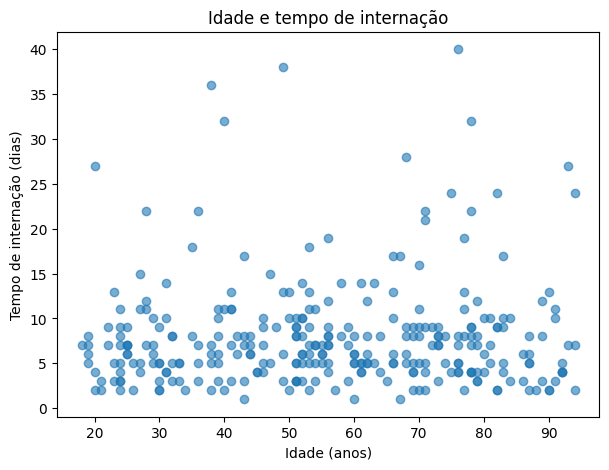

In [32]:
plt.figure(figsize=(7, 5))
plt.scatter(df["idade"], df["tempo_internacao_dias"], alpha=0.6)
plt.xlabel("Idade (anos)")
plt.ylabel("Tempo de internação (dias)")
plt.title("Idade e tempo de internação")
plt.show()

### Mapa de calor de uma tabela cruzada

**Pergunta:** como a proporção de readmissão se distribui entre os serviços?

Matriz:

In [23]:
tab = pd.crosstab(
    df["servico"],
    df["readmissao_30d"],
    normalize="index"
)

Gráfico (a cor representa magnitude; a barra de cores é obrigatória):

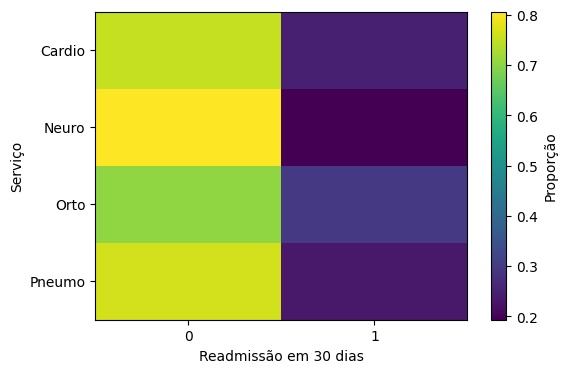

In [24]:
plt.figure(figsize=(6, 4))

plt.imshow(tab.values, aspect="auto")  # Cria o mapa de calor; aspect="auto" ajusta automaticamente a proporção das células ao espaço disponível

plt.colorbar(label="Proporção")  # Adiciona a barra de cores indicando as proporções

plt.xticks(range(len(tab.columns)), tab.columns)  # Define os rótulos do eixo X

plt.yticks(range(len(tab.index)), tab.index)  # Define os rótulos do eixo Y

plt.xlabel("Readmissão em 30 dias")  # Nomeia o eixo X

plt.ylabel("Serviço")  # Nomeia o eixo Y

plt.show()  # Exibe o gráfico

### Matriz de correlação

**Pergunta:** como idade, tempo de internação e internações anteriores variam juntos?

> A coluna se chama `internacoes_anteriores`, como na Aula 8.

Matriz:

In [25]:
variaveis = [
    "idade",
    "tempo_internacao_dias",
    "internacoes_anteriores"
]
corr = df[variaveis].corr()

Gráfico (`vmin=-1` e `vmax=1` fixam a escala de cores):

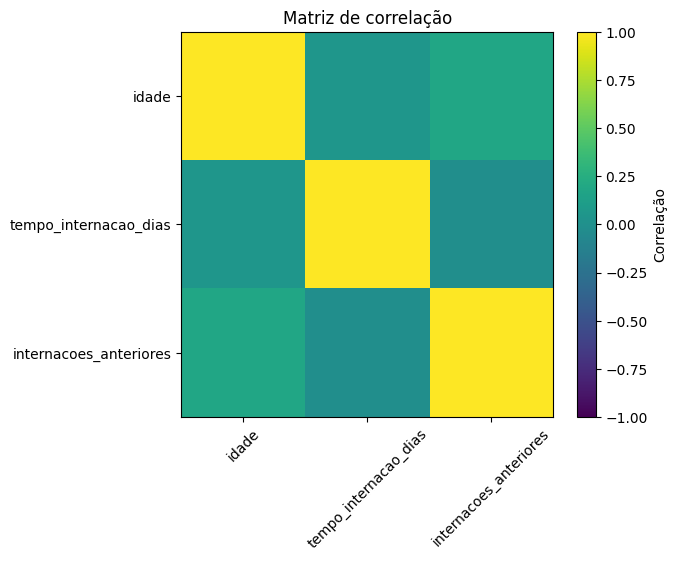

In [26]:
plt.figure(figsize=(6, 5))
plt.imshow(corr.values, vmin=-1, vmax=1,
           aspect="auto")
plt.colorbar(label="Correlação")
plt.xticks(range(len(variaveis)), variaveis,
           rotation=45)
plt.yticks(range(len(variaveis)), variaveis)
plt.title("Matriz de correlação")
plt.show()

## Exercícios




## Exercício 1 — Distribuição da idade

**Pergunta:** como se distribui a idade dos pacientes da base?

Faça um **histograma** da idade com `bins=10` e outro com `bins=25`.

## Exercício 2 — Comparando grupos

**Pergunta:** pacientes readmitidos em 30 dias tinham mais internações anteriores do que os não readmitidos?

Faça **boxplots lado a lado** de `internacoes_anteriores` para cada valor de `readmissao_30d` (0 e 1).

## Exercício 3 — Proporção por categoria

**Pergunta:** qual faixa etária tem a maior proporção de readmissão em 30 dias?

Calcule a proporção de readmissão por `faixa_etaria` e ordene do maior para o menor.